# NB02 — Site and weather assessment

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Understand the site before optimising: weather, load vs PV (annual, monthly, daily), the evening/overnight gap a battery
can fill, PV performance against irradiance (implied size, clipping), a timing check, the tariffs and wholesale prices, and the bills
**without** a battery (Scenario 0 (S0) no PV, Scenario 1 (S1) PV only).

**Input:** `outputs/nb01_clean_2022_2023.csv` (from NB01).
**Outputs** (`outputs/`): `nb02_site_summary.csv`, `nb02_monthly.csv`, `nb02_sizing_inputs.csv`, `nb02_pv_irradiance_bins.csv`,
`nb02_bills_S0_S1.csv`, and figures in `outputs/figures/` (fig02–fig06).

**Course basis:** Workshop week 1 (resampling, daily profiles, bill function); Workshop week 4 visualisation helpers (story window, month × time heatmap,
load duration curve); Topic 3 slides 12–13 sizing inputs; Topic 4 slide 8 PV model.

## Cell 0 — Settings
Same settings cell as every notebook (Colab or local).

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports, plot style and the clean data
**Colours** are fixed here and reused in every notebook

In [2]:
# Cell 1 - imports, constants, load clean data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DT_H = 5 / 60                                   # hours per 5-min interval
PR = 0.85                                       # performance ratio (metadata)
COL = {'load': '#1f4e79', 'pv': '#f2a900', 'net': '#7f7f7f', 'temp': '#c00000',
       'flat': '#4c72b0', 'tou': '#55a868', 'wholesale': '#c44e52'}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime'])
df['month'] = df['datetime'].dt.month
df['hour'] = df['datetime'].dt.hour
df['date'] = df['datetime'].dt.date
df['net_load_kw'] = df['load_kw'] - df['pv_actual_kw']
print(df.shape, df['datetime'].min(), '->', df['datetime'].max())

def save_fig(fig, name):
    # save a figure as PNG (200 dpi) for the report
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches='tight')

(210240, 30) 2022-01-01 00:00:00 -> 2023-12-31 23:55:00


## Cell 2 — Weather summary
**Purpose:** . Annual and monthly mean temperature and global horizontal irradiation (GHI).
GHI energy: W/m² × 5/60 h ÷ 1000 = kWh/m².

In [3]:
# Cell 2 - weather summary
weather_year = df.groupby('year').agg(
    temp_mean_c=('temperature_c', 'mean'), temp_min_c=('temperature_c', 'min'), temp_max_c=('temperature_c', 'max'),
    ghi_kwh_m2=('irradiance_wm2', lambda s: s.sum() * DT_H / 1000))
print(weather_year.round(1))

weather_month = df.groupby(['year', 'month']).agg(
    temp_mean_c=('temperature_c', 'mean'),
    ghi_kwh_m2=('irradiance_wm2', lambda s: s.sum() * DT_H / 1000)).reset_index()
weather_month_avg = weather_month.groupby('month')[['temp_mean_c', 'ghi_kwh_m2']].mean()
print('\nTwo-year monthly average:')
print(weather_month_avg.round(1).T)

      temp_mean_c  temp_min_c  temp_max_c  ghi_kwh_m2
year                                                 
2022         16.6         1.8        32.3      1799.5
2023         17.8         3.5        34.7      1963.9

Two-year monthly average:
month           1      2      3      4      5      6      7      8      9      10     11     12
temp_mean_c   21.7   21.2   21.1   17.8   14.5   11.8   11.5   13.3   15.5   17.9   19.0   21.4
ghi_kwh_m2   194.3  168.1  163.1  138.6  107.3  108.3  106.9  136.2  158.5  187.0  193.5  220.0


## Cell 3 — Annual and monthly energy: load vs PV
**Purpose:** annual load total, annual PV and the monthly picture.
2022 PV = measured; 2023 PV = commercial forecast treated as actual (brief).

      load_mwh  pv_mwh  load_peak_kw  pv_peak_kw  load_kwh_per_day  pv_to_load_ratio
year                                                                                
2022     11.20   19.09          7.43       14.55             30.68              1.70
2023     11.22   21.25          7.43       11.58             30.73              1.89


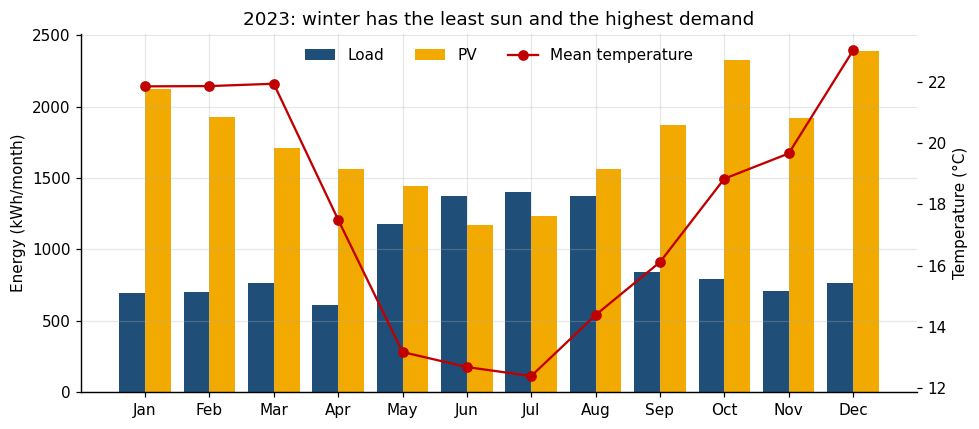

In [4]:
# Cell 3 - annual and monthly energy
annual = df.groupby('year').agg(
    load_mwh=('load_kw', lambda s: s.sum() * DT_H / 1000),
    pv_mwh=('pv_actual_kw', lambda s: s.sum() * DT_H / 1000),
    load_peak_kw=('load_kw', 'max'),
    pv_peak_kw=('pv_actual_kw', 'max'))
annual['load_kwh_per_day'] = annual['load_mwh'] * 1000 / df.groupby('year')['date'].nunique()
annual['pv_to_load_ratio'] = annual['pv_mwh'] / annual['load_mwh']
print(annual.round(2))

monthly = df.groupby(['year', 'month']).agg(
    load_kwh=('load_kw', lambda s: s.sum() * DT_H),
    pv_kwh=('pv_actual_kw', lambda s: s.sum() * DT_H),
    temp_mean_c=('temperature_c', 'mean')).reset_index()

# Fig 2: evaluation year 2023, monthly load vs PV bars + mean temperature line
m23 = monthly[monthly.year == 2023]
x = np.arange(12)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, m23.load_kwh, 0.4, color=COL['load'], label='Load')
ax.bar(x + 0.2, m23.pv_kwh, 0.4, color=COL['pv'], label='PV')
ax.set_xticks(x, ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_ylabel('Energy (kWh/month)')
ax2 = ax.twinx(); ax2.plot(x, m23.temp_mean_c, color=COL['temp'], marker='o', label='Mean temperature')
ax2.set_ylabel('Temperature (°C)'); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper center', ncol=3, frameon=False)
ax.set_title('2023: winter has the least sun and the highest demand')
plt.tight_layout(); save_fig(fig, 'fig02_monthly_load_pv_temp_2023.png'); plt.show()

## Cell 3b — Data check: is the 2023 load the same as 2022?
**Purpose:** check whether the load profile was repeated. If it is, year-on-year
differences in bills come only from PV and prices — the load profile looks synthetic, scaled ×30.7 according to the metadata.

In [5]:
# Cell 3b - compare 2022 and 2023 load interval by interval (same position in the year)
l22 = df.loc[df.year == 2022, 'load_kw'].to_numpy()
l23 = df.loc[df.year == 2023, 'load_kw'].to_numpy()
same = np.isclose(l22, l23)
print('Share of 5-min intervals with identical load in 2022 and 2023: %.1f %%' % (100 * same.mean()))
print('Correlation: %.4f' % np.corrcoef(l22, l23)[0, 1])
print('(Remaining differences come mainly from the filled gaps, which differ between the years.)')

Share of 5-min intervals with identical load in 2022 and 2023: 99.1 %
Correlation: 0.9957
(Remaining differences come mainly from the filled gaps, which differ between the years.)


## Cell 4 — Average summer vs winter day (Workshop Week 4 story)
**Purpose:** show *when* energy is needed vs produced. The evening/overnight gap is what the battery can fill.
Summer = Dec–Feb, winter = Jun–Aug, 2023, 30-min means.

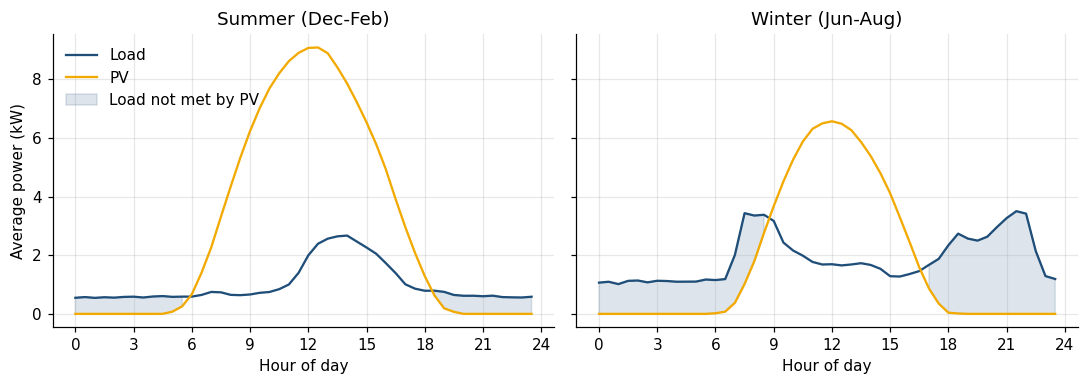

In [6]:
# Cell 4 - average day profiles, summer vs winter (2023)
d23 = df[df.year == 2023].copy()
d23['slot'] = d23['datetime'].dt.hour + (d23['datetime'].dt.minute // 30) * 0.5
season = {12: 'Summer (Dec-Feb)', 1: 'Summer (Dec-Feb)', 2: 'Summer (Dec-Feb)',
          6: 'Winter (Jun-Aug)', 7: 'Winter (Jun-Aug)', 8: 'Winter (Jun-Aug)'}
d23['season'] = d23['month'].map(season)
prof = d23.dropna(subset=['season']).groupby(['season', 'slot'])[['load_kw', 'pv_actual_kw']].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, s in zip(axes, ['Summer (Dec-Feb)', 'Winter (Jun-Aug)']):
    p = prof.loc[s]
    ax.plot(p.index, p.load_kw, color=COL['load'], label='Load')
    ax.plot(p.index, p.pv_actual_kw, color=COL['pv'], label='PV')
    ax.fill_between(p.index, p.load_kw, p.pv_actual_kw, where=p.load_kw > p.pv_actual_kw, color=COL['load'], alpha=0.15, label='Load not met by PV')
    ax.set_title(s); ax.set_xlabel('Hour of day'); ax.set_xticks(range(0, 25, 3))
axes[0].set_ylabel('Average power (kW)'); axes[0].legend(frameon=False)
plt.tight_layout(); save_fig(fig, 'fig03_average_day_summer_winter_2023.png'); plt.show()

## Cell 5 — Week 4 helpers: month × half-hour heatmap and load duration curve
**Purpose:** the heatmap shows the seasonal and daily shape of net load (load − PV) at once; the load duration curve shows how often
the house exports (net load < 0). Functions follow the Week 4 docstrings, with `solar_kw` → `pv_actual_kw`, after resampling to 30 min.

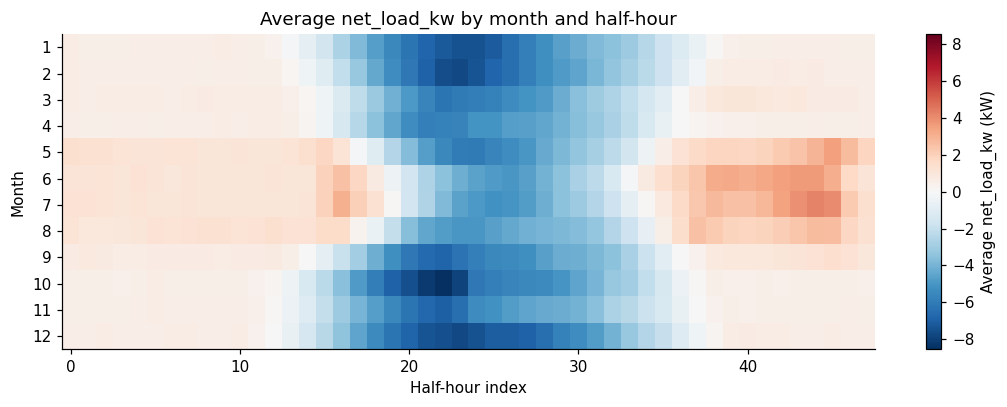

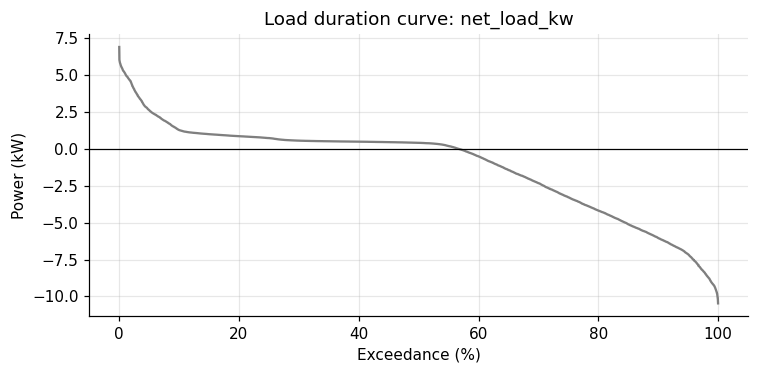

Share of 30-min periods with net export (net load < 0), 2023: 43.4 %


In [7]:
# Cell 5 - Week 4 style helpers
def prepare_visualization_data(df5):
    # Week 4 Task 1: 30-min table with net load, month and half-hour index
    d = df5.set_index('datetime')[['load_kw', 'pv_actual_kw']].resample('30min', label='right', closed='right').mean().reset_index()
    d['net_load_kw'] = d['load_kw'] - d['pv_actual_kw']
    d['month'] = d['datetime'].dt.month
    d['half_hour_index'] = d['datetime'].dt.hour * 2 + d['datetime'].dt.minute // 30
    return d

def plot_month_time_heatmap(d, value_col='net_load_kw'):
    # Week 4 Task 4: 12 x 48 matrix of mean value_col
    mat = d.pivot_table(index='month', columns='half_hour_index', values=value_col, aggfunc='mean').reindex(index=range(1, 13), columns=range(48))
    lim = np.nanmax(np.abs(mat.values))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    im = ax.imshow(mat.values, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.set_title(f'Average {value_col} by month and half-hour'); ax.set_xlabel('Half-hour index'); ax.set_ylabel('Month')
    ax.set_yticks(range(12), range(1, 13)); ax.grid(False)
    fig.colorbar(im, ax=ax, label=f'Average {value_col} (kW)')
    return fig

def plot_load_duration_curve(d, value_col='net_load_kw'):
    # Week 4 Task 5: values sorted descending against exceedance %
    y = np.sort(d[value_col].dropna().values)[::-1]
    xs = np.arange(1, len(y) + 1) / len(y) * 100
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(xs, y, color=COL['net']); ax.axhline(0, color='k', lw=0.8)
    ax.set_title(f'Load duration curve: {value_col}'); ax.set_xlabel('Exceedance (%)'); ax.set_ylabel('Power (kW)')
    return fig

v23 = prepare_visualization_data(df[df.year == 2023])
fig = plot_month_time_heatmap(v23); plt.tight_layout(); save_fig(fig, 'fig04_net_load_heatmap_2023.png'); plt.show()
fig = plot_load_duration_curve(v23); plt.tight_layout(); plt.show()
print('Share of 30-min periods with net export (net load < 0), 2023: %.1f %%' % (100 * (v23.net_load_kw < 0).mean()))

## Cell 6 — Sizing inputs: overnight load and daily PV surplus (Topic 3 slides 12–13)
**Purpose:** the energy view of battery sizing
- **Overnight need:** load from 16:00 to 08:00 the next morning (when PV cannot cover the house).
- **Daily surplus:** PV energy above load during the day (what is available to charge the battery for free).
- **Evening power:** load between 16:00 and 22:00 (kW) vs a 5 kW battery inverter.

In [8]:
# Cell 6 - sizing inputs
def overnight_need_kwh(d):
    # energy of load from 16:00 on day D to 08:00 on day D+1 (kWh), labelled by day D
    s = d.set_index('datetime')['load_kw']
    evening = s[(s.index.hour >= 16)]
    morning = s[(s.index.hour < 8)]
    e = evening.groupby(evening.index.date).sum() * DT_H
    m = morning.groupby((morning.index - pd.Timedelta(days=1)).date).sum() * DT_H
    return (e + m).dropna()

rows = []
for yr in [2022, 2023]:
    d = df[df.year == yr]
    need = overnight_need_kwh(d)
    surplus = (d['pv_actual_kw'] - d['load_kw']).clip(lower=0).groupby(d['date']).sum() * DT_H
    evening_kw = d.loc[(d.hour >= 16) & (d.hour < 22), 'load_kw']
    rows.append({'year': yr,
                 'overnight_need_kWh_P50': need.median(), 'overnight_need_kWh_P75': need.quantile(.75), 'overnight_need_kWh_P90': need.quantile(.9),
                 'daily_surplus_kWh_P10': surplus.quantile(.1), 'daily_surplus_kWh_P50': surplus.median(),
                 'share_days_surplus_ge_13.5kWh': (surplus >= 13.5).mean(),
                 'evening_load_kW_P95': evening_kw.quantile(.95), 'share_evening_load_le_5kW': (evening_kw <= 5).mean()})
sizing = pd.DataFrame(rows).set_index('year')
print(sizing.round(2).T)

year                            2022   2023
overnight_need_kWh_P50         10.58  10.54
overnight_need_kWh_P75         23.17  23.17
overnight_need_kWh_P90         32.98  32.98
daily_surplus_kWh_P10          12.33  20.79
daily_surplus_kWh_P50          33.69  41.44
share_days_surplus_ge_13.5kWh   0.89   0.95
evening_load_kW_P95             4.79   4.79
share_evening_load_le_5kW       0.96   0.96


## Cell 7 — PV vs irradiance: implied size and clipping check
**Purpose:** test PV performance against irradiance using the 2022 **measured** PV.
- **Implied size:** PV ÷ (G/1000) at high irradiance ≈ kWp × PR × temperature factor → kWp ≈ ratio ÷ 0.85.
- **Clipping:** an inverter limit shows up as a flat ceiling in PV at high irradiance. gentle fall is just the temperature effect.

                    n  ratio_median  pv_p99_kw
irradiance_wm2                                
(50, 200]       11095         11.05       2.41
(200, 400]      11441         10.92       4.90
(400, 600]      11510         10.89       7.46
(600, 800]       8987         10.83       9.83
(800, 900]       2880         10.68      11.32
(900, 1000]      1534         10.58      12.57
(1000, 1400]      812         10.59      13.94

ratio at G>500 W/m2: median 10.78, P95 12.63 kW per kW/m2 -> implied DC size ~ 12.7 kWp (at PR 0.85)
max measured PV 14.55 kW; intervals > 12 kW: 232
Low-output intervals (G > 600 W/m2, PV < 65 % of expected): 661 of 14213 (4.7 %), spread over 238 days
  by hour of day: {8: 11, 9: 53, 10: 87, 11: 131, 12: 143, 13: 126, 14: 76, 15: 31, 16: 3}


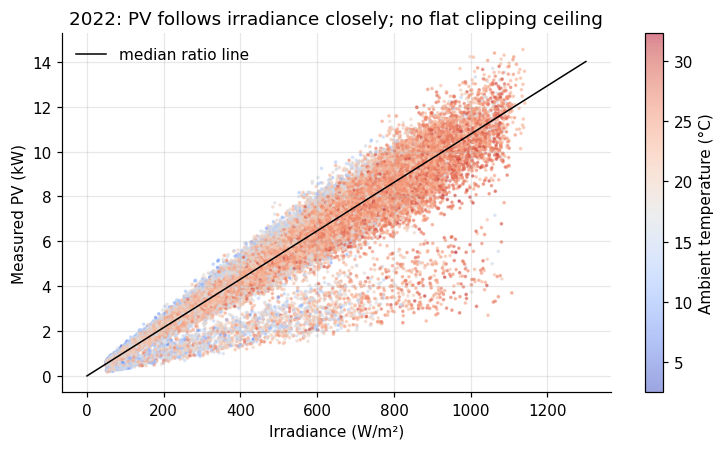

In [9]:
# Cell 7 - PV vs irradiance (2022 measured)
d22 = df[(df.year == 2022) & (df.irradiance_wm2 > 50)].copy()
d22['ratio'] = d22['pv_measured_kw'] / (d22['irradiance_wm2'] / 1000)
bins = pd.cut(d22['irradiance_wm2'], [50, 200, 400, 600, 800, 900, 1000, 1400])
pv_bins = d22.groupby(bins, observed=True).agg(n=('ratio', 'size'), ratio_median=('ratio', 'median'),
                                               pv_p99_kw=('pv_measured_kw', lambda s: s.quantile(.99)))
print(pv_bins.round(2))
hi = d22[d22.irradiance_wm2 > 500]
print('\nratio at G>500 W/m2: median %.2f, P95 %.2f kW per kW/m2 -> implied DC size ~ %.1f kWp (at PR %.2f)'
      % (hi.ratio.median(), hi.ratio.quantile(.95), hi.ratio.median() / PR, PR))
print('max measured PV %.2f kW; intervals > 12 kW: %d' % (d22.pv_measured_kw.max(), (d22.pv_measured_kw > 12).sum()))

# lower branch in the scatter: PV far below the median line at high irradiance
hi600 = d22[d22.irradiance_wm2 > 600]
low = hi600[hi600.ratio < 0.65 * hi600.ratio.median()]
print('Low-output intervals (G > 600 W/m2, PV < 65 %% of expected): %d of %d (%.1f %%), spread over %d days'
      % (len(low), len(hi600), 100 * len(low) / len(hi600), low.date.nunique()))
print('  by hour of day:', low.datetime.dt.hour.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(d22.irradiance_wm2, d22.pv_measured_kw, c=d22.temperature_c, s=2, cmap='coolwarm', alpha=0.5)
gg = np.linspace(0, 1300, 50)
ax.plot(gg, hi.ratio.median() * gg / 1000, color='k', lw=1, label='median ratio line')
ax.set_xlabel('Irradiance (W/m²)'); ax.set_ylabel('Measured PV (kW)')
ax.set_title('2022: PV follows irradiance closely; no flat clipping ceiling')
fig.colorbar(sc, ax=ax, label='Ambient temperature (°C)'); ax.legend(frameon=False)
plt.tight_layout(); save_fig(fig, 'fig05_pv_vs_irradiance_2022.png'); plt.show()

**Interpretation of the lower branch:** about 5 % of high-irradiance intervals show PV at 40–65 % of the expected value. They are scattered
over many days (no whole day affected) and concentrated around midday. Likely causes: a passing cloud shading the array but not the irradiance
sensor (or the reverse), or the inverter reducing power at midday (e.g. volt-watt response to high network voltage). They are real behaviour,
not flagged by the Week 1 rule, and are **kept**. Two consequences: the PV model trained on 2022 will show some large errors there, and the 2023
commercial PV (our "actual") contains no such events — one sentence in the forecast discussion.

## Cell 8 — Timing check: solar noon
**Purpose:** a data-quality check. For a correct AEST timeline in Toowoomba (151.95°E), the middle of each day's sunlight should fall
near astronomical solar noon (≈ 11:52 minus the equation of time). This is only a check, **nothing is shifted**.

In [10]:
# Cell 8 - sunrise/sunset midpoint vs astronomical solar noon
def solar_noon_minutes(day):
    # approximate solar noon (minutes after midnight, AEST) at 151.95 E using the equation of time
    n = pd.Timestamp(day).dayofyear
    b = 2 * np.pi * (n - 81) / 364
    eot = 9.87 * np.sin(2 * b) - 7.53 * np.cos(b) - 1.5 * np.sin(b)
    return 12 * 60 - 4 * (151.95 - 150.0) - eot

rows = []
for day, g in df.groupby('date'):
    lit = g[g.irradiance_wm2 > 5]
    if len(g) < 288 or len(lit) == 0:
        continue
    mins = lit.datetime.dt.hour * 60 + lit.datetime.dt.minute
    rows.append({'date': pd.Timestamp(day), 'offset_min': (mins.min() + mins.max()) / 2 - solar_noon_minutes(day)})
noon = pd.DataFrame(rows).set_index('date')
print('Median offset of the sunlight midpoint after astronomical solar noon: %.0f min' % noon.offset_min.median())
print(noon.offset_min.groupby(noon.index.month).median().round(0).rename('median offset by month (min)').to_frame().T)

Median offset of the sunlight midpoint after astronomical solar noon: 31 min
date                            1     2     3     4     5     6     7     8     9     10    11    12
median offset by month (min)  31.0  36.0  28.0  30.0  25.0  36.0  32.0  29.0  40.0  27.0  25.0  36.0


## Cell 9 — Tariffs and wholesale prices
**Purpose:** confirm the ToU windows, and describe the spot price in both years (negative share, spikes, daily shape) and the
resulting wholesale-passthrough import price.

ToU import price by hour: {0: 0.15, 1: 0.15, 2: 0.15, 3: 0.15, 4: 0.15, 5: 0.15, 6: 0.15, 7: 0.25, 8: 0.25, 9: 0.25, 10: 0.25, 11: 0.25, 12: 0.25, 13: 0.25, 14: 0.25, 15: 0.25, 16: 0.25, 17: 0.25, 18: 0.25, 19: 0.4, 20: 0.4, 21: 0.4, 22: 0.4, 23: 0.15}
Network ToU by hour: {0: 0.04947, 1: 0.04947, 2: 0.04947, 3: 0.04947, 4: 0.04947, 5: 0.04947, 6: 0.04947, 7: 0.04947, 8: 0.04947, 9: 0.03163, 10: 0.03163, 11: 0.03163, 12: 0.03163, 13: 0.03163, 14: 0.03163, 15: 0.03163, 16: 0.16734, 17: 0.16734, 18: 0.16734, 19: 0.16734, 20: 0.16734, 21: 0.04947, 22: 0.04947, 23: 0.04947}
       mean  median    min   max  negative_share  n_above_1  n_above_5  wholesale_import_mean
year                                                                                         
2022  0.205   0.137 -1.000  15.5           0.045        742        248                  0.336
2023  0.091   0.076 -0.355  15.5           0.135        174         60                  0.202


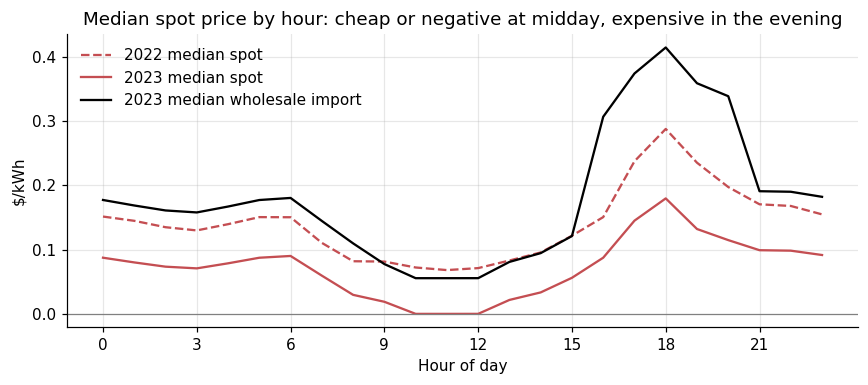

In [11]:
# Cell 9 - tariff windows and price statistics
print('ToU import price by hour:', df.groupby('hour')['import_tou_aud_kwh'].first().to_dict())
print('Network ToU by hour:', df.groupby('hour')['network_aud_kwh'].first().to_dict())

price_stats = df.groupby('year')['spot_aud_kwh'].agg(
    mean='mean', median='median', min='min', max='max',
    negative_share=lambda s: (s < 0).mean(), n_above_1=lambda s: (s > 1).sum(), n_above_5=lambda s: (s > 5).sum())
price_stats['wholesale_import_mean'] = df.groupby('year')['import_wholesale_aud_kwh'].mean()
print(price_stats.round(3))

prof_p = df.groupby(['year', 'hour'])['spot_aud_kwh'].median().unstack(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
for yr, ls in [(2022, '--'), (2023, '-')]:
    ax.plot(prof_p.index, prof_p[yr], ls, color=COL['wholesale'], label=f'{yr} median spot')
ax.plot(prof_p.index, df[df.year == 2023].groupby('hour')['import_wholesale_aud_kwh'].median(), color='k', label='2023 median wholesale import')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('Hour of day'); ax.set_ylabel('$/kWh'); ax.set_xticks(range(0, 24, 3))
ax.set_title('Median spot price by hour: cheap or negative at midday, expensive in the evening')
ax.legend(frameon=False); plt.tight_layout(); save_fig(fig, 'fig06_price_daily_profile.png'); plt.show()

## Cell 10 — Bills without a battery: S0 (no PV) and S1 (PV only), 2023
net load = load − PV; import = max(net, 0); export = max(−net, 0);
bill = Σ (import × import price − export × export price) × 5/60. Energy charges only (daily supply charges excluded in every tariff);
the $300/yr VPP fee is **not** included here because S0/S1 have no VPP service.
- **Solar savings** = S0 − S1.
- **Self-consumption** = (PV − export) / PV; **self-sufficiency** = 1 − import / load.

           S0_no_pv_aud  S1_pv_only_aud  solar_saving_aud  export_revenue_S1_aud  import_kwh_S1  export_kwh_S1  self_consumption_S1  self_sufficiency_S1
tariff                                                                                                                                                  
flat            3365.23          794.69           2570.54                 760.77        5184.85       15215.31                 0.28                 0.54
tou             2875.68          618.44           2257.24                 760.77        5184.85       15215.31                 0.28                 0.54
wholesale       2141.85         1023.30           1118.55                 347.39        5184.85       15215.31                 0.28                 0.54


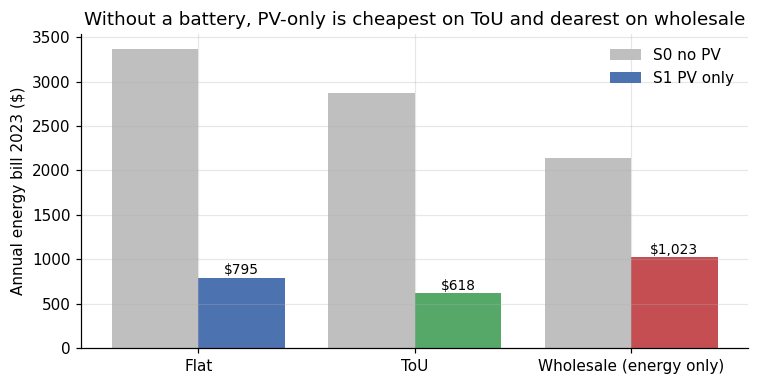

In [12]:
# Cell 10 - bills S0 and S1 for each tariff (2023)
def bill_no_battery(d, imp_col, exp_col, with_pv=True):
    # energy bill ($) without a battery; with_pv=False gives S0 (all load imported)
    net = d['load_kw'] - (d['pv_actual_kw'] if with_pv else 0)
    imp, exp = net.clip(lower=0), (-net).clip(lower=0)
    return float(((imp * d[imp_col] - exp * d[exp_col]) * DT_H).sum()), imp, exp

d = df[df.year == 2023]
rows = []
for tariff in ['flat', 'tou', 'wholesale']:
    ic, ec = f'import_{tariff}_aud_kwh', f'export_{tariff}_aud_kwh'
    s0, _, _ = bill_no_battery(d, ic, ec, with_pv=False)
    s1, imp, exp = bill_no_battery(d, ic, ec, with_pv=True)
    rows.append({'tariff': tariff, 'S0_no_pv_aud': s0, 'S1_pv_only_aud': s1, 'solar_saving_aud': s0 - s1,
                 'export_revenue_S1_aud': float((exp * d[ec] * DT_H).sum()),
                 'import_kwh_S1': float(imp.sum() * DT_H), 'export_kwh_S1': float(exp.sum() * DT_H)})
bills = pd.DataFrame(rows).set_index('tariff')
pv_kwh, load_kwh = d.pv_actual_kw.sum() * DT_H, d.load_kw.sum() * DT_H
bills['self_consumption_S1'] = 1 - bills['export_kwh_S1'] / pv_kwh
bills['self_sufficiency_S1'] = 1 - bills['import_kwh_S1'] / load_kwh
print(bills.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
xx = np.arange(3)
ax.bar(xx - 0.2, bills.S0_no_pv_aud, 0.4, color='#bfbfbf', label='S0 no PV')
ax.bar(xx + 0.2, bills.S1_pv_only_aud, 0.4, color=[COL[t] for t in bills.index], label='S1 PV only')
for i, v in enumerate(bills.S1_pv_only_aud):
    ax.text(i + 0.2, v + 40, f'${v:,.0f}', ha='center', fontsize=9)
ax.set_xticks(xx, ['Flat', 'ToU', 'Wholesale (energy only)'])
ax.set_ylabel('Annual energy bill 2023 ($)'); ax.legend(frameon=False)
ax.set_title('Without a battery, PV-only is cheapest on ToU and dearest on wholesale')
plt.tight_layout(); plt.show()

## Cell 11 — Save summary tables
**Purpose:** later notebooks and the report read these numbers instead of recomputing them.

In [13]:
# Cell 11 - save tables
site_summary = annual.join(weather_year)
site_summary.to_csv(os.path.join(OUT_DIR, 'nb02_site_summary.csv'))
monthly.merge(weather_month, on=['year', 'month'], suffixes=('', '_w')).to_csv(os.path.join(OUT_DIR, 'nb02_monthly.csv'), index=False)
sizing.to_csv(os.path.join(OUT_DIR, 'nb02_sizing_inputs.csv'))
pv_bins.to_csv(os.path.join(OUT_DIR, 'nb02_pv_irradiance_bins.csv'))
bills.to_csv(os.path.join(OUT_DIR, 'nb02_bills_S0_S1.csv'))
print('Saved tables:', sorted(f for f in os.listdir(OUT_DIR) if f.startswith('nb02')))
print('Saved figures:', sorted(os.listdir(FIG_DIR)))

Saved tables: ['nb02_bills_S0_S1.csv', 'nb02_monthly.csv', 'nb02_pv_irradiance_bins.csv', 'nb02_site_summary.csv', 'nb02_sizing_inputs.csv']
Saved figures: ['fig02_monthly_load_pv_temp_2023.png', 'fig03_average_day_summer_winter_2023.png', 'fig04_net_load_heatmap_2023.png', 'fig05_pv_vs_irradiance_2022.png', 'fig06_price_daily_profile.png']


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai, 21 Nov 2026 |
| What AI did | Drafted this notebook from my notes workshop Week 4 helper docstrings) |
| Example prompt | “notebook 1 done and saved to github. draft notebook 2” |
| How I checked it | ran it in Colab; compared totals with notebook 1 and Notes; checked the S0 bill by hand (load × price); looked at every figure |